<a href="https://colab.research.google.com/github/JananiPerumal25/Lightweight-deep-learning-model-for-skin-disease-detection-/blob/main/Skin_Disease_EfficientNet_GAT.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Lightweight Explainable Skin Disease Detection
**EfficientNet-B2 → Patch Graph → Graph Attention Network (GAT) → Classifier → Grad-CAM**
Dataset: HAM10000 (10,015 dermatoscopic images, 7 classes).

**Before you start:** `Runtime → Change runtime type → T4 GPU`, then run the cells top to bottom.

> This is a screening / decision-support research project, not a medical diagnosis tool.

## 1. Setup

In [ ]:
import os, glob, random, shutil, zipfile, time
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

import torch, torch.nn as nn, torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision import models, transforms
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, balanced_accuracy_score
from google.colab import files, drive

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device, "|", torch.cuda.get_device_name(0) if device.type == "cuda" else "NO GPU - enable T4 runtime!")

Device: cuda | Tesla T4


## 2. Data acquisition (Kaggle)
Kaggle now gives you an **API token** (a long text starting with `KGAT_`) instead of a downloaded file.
1. On kaggle.com open **Settings → API → Generate New Token** and **copy** the token.
2. Run the cell below and **paste** the token into the box that appears, then press Enter.

*(Have an old `kaggle.json` instead? Just run the cell below and leave the box empty, then upload the file.)*

In [ ]:
!pip install -q -U kaggle
import getpass
token = getpass.getpass("Paste your Kaggle API token here (KGAT_...), or leave empty to upload kaggle.json: ").strip()
if token:
    os.environ["KAGGLE_API_TOKEN"] = token
    print("Token set.")
else:
    files.upload()
    os.makedirs("/root/.kaggle", exist_ok=True)
    shutil.copy("kaggle.json", "/root/.kaggle/kaggle.json")
    os.chmod("/root/.kaggle/kaggle.json", 0o600)
    print("kaggle.json installed.")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 126.2/126.2 kB 4.6 MB/s eta 0:00:00
Paste your Kaggle API token here (KGAT_...), or leave empty to upload kaggle.json: ··········
Token set.


In [ ]:
!kaggle datasets download -d kmader/skin-cancer-mnist-ham10000 -p /content/data
with zipfile.ZipFile("/content/data/skin-cancer-mnist-ham10000.zip") as z:
    z.extractall("/content/data/ham10000")
print(os.listdir("/content/data/ham10000"))

Dataset URL: https://www.kaggle.com/datasets/kmader/skin-cancer-mnist-ham10000
License(s): CC-BY-NC-SA-4.0
100% 5.20G/5.20G [00:52<00:00, 106MB/s]

['ham10000_images_part_1', 'hmnist_8_8_RGB.csv', 'hmnist_28_28_RGB.csv', 'HAM10000_metadata.csv', 'hmnist_8_8_L.csv', 'HAM10000_images_part_2', 'ham10000_images_part_2', 'HAM10000_images_part_1', 'hmnist_28_28_L.csv']


## 3. Data understanding

Total samples: 10015
dx
nv       6705
mel      1113
bkl      1099
bcc       514
akiec     327
vasc      142
df        115
Name: count, dtype: int64


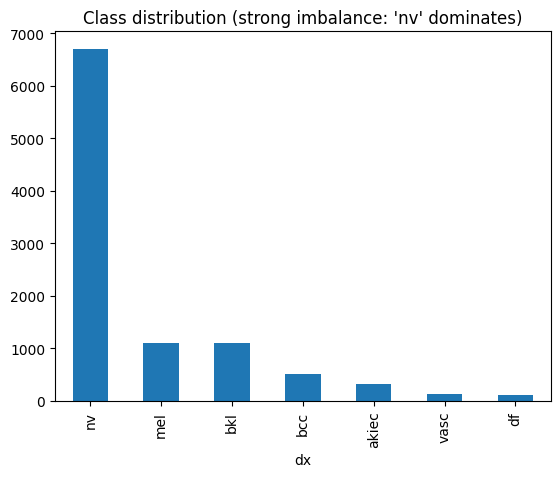

In [ ]:
ROOT = "/content/data/ham10000"
df = pd.read_csv(f"{ROOT}/HAM10000_metadata.csv")
print("Total samples:", len(df))

# map image_id -> file path
path_map = {os.path.splitext(os.path.basename(p))[0]: p
            for p in glob.glob(f"{ROOT}/**/*.jpg", recursive=True)}
df["path"] = df["image_id"].map(path_map)
assert df["path"].notna().all(), "Some images were not found"

full_names = {"akiec": "Actinic keratoses / Bowen's disease", "bcc": "Basal cell carcinoma",
              "bkl": "Benign keratosis", "df": "Dermatofibroma",
              "mel": "Melanoma", "nv": "Melanocytic nevi", "vasc": "Vascular lesions"}
classes = sorted(df["dx"].unique())
class_to_idx = {c: i for i, c in enumerate(classes)}
df["label"] = df["dx"].map(class_to_idx)

counts = df["dx"].value_counts()
print(counts)
counts.plot(kind="bar", title="Class distribution (strong imbalance: 'nv' dominates)")
plt.show()

## 4. Preprocessing & split
* Images resized to 224×224, normalised with ImageNet mean/std (required for the pretrained EfficientNet; this replaces the plain 0–1 rescale).
* **80/20 split grouped by `lesion_id`**: HAM10000 has several photos of the same lesion, so a random split would leak near-duplicates into validation and inflate accuracy.

In [ ]:
from sklearn.model_selection import StratifiedGroupKFold
sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
tr_idx, va_idx = next(sgkf.split(df, df["label"], groups=df["lesion_id"]))
train_df, val_df = df.iloc[tr_idx].reset_index(drop=True), df.iloc[va_idx].reset_index(drop=True)
print(len(train_df), "train |", len(val_df), "val")

IMG = 256   # higher resolution keeps fine lesion texture (T4 handles this fine)
mean, std = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]
train_tf = transforms.Compose([
    transforms.Resize((IMG, IMG)),
    transforms.RandomHorizontalFlip(), transforms.RandomVerticalFlip(),
    transforms.RandomRotation(20),
    transforms.ColorJitter(0.2, 0.2, 0.2, 0.02),
    transforms.ToTensor(), transforms.Normalize(mean, std)])
val_tf = transforms.Compose([
    transforms.Resize((IMG, IMG)), transforms.ToTensor(), transforms.Normalize(mean, std)])

class SkinDS(Dataset):
    def __init__(self, d, tf): self.paths, self.labels, self.tf = d["path"].tolist(), d["label"].tolist(), tf
    def __len__(self): return len(self.paths)
    def __getitem__(self, i):
        return self.tf(Image.open(self.paths[i]).convert("RGB")), self.labels[i]

BATCH = 32
train_dl = DataLoader(SkinDS(train_df, train_tf), batch_size=BATCH, shuffle=True,  num_workers=2, pin_memory=True)
val_dl   = DataLoader(SkinDS(val_df,   val_tf),   batch_size=BATCH, shuffle=False, num_workers=2, pin_memory=True)

# class weights to counter imbalance (softened inverse frequency)
cnt = np.bincount(train_df["label"], minlength=len(classes))
cw = torch.tensor((cnt.sum() / (len(classes) * cnt)) ** 0.5, dtype=torch.float32).to(device)
print("class weights:", dict(zip(classes, cw.cpu().numpy().round(2))))

8001 train | 2014 val
class weights: {'akiec': np.float32(2.1), 'bcc': np.float32(1.66), 'bkl': np.float32(1.13), 'df': np.float32(3.51), 'mel': np.float32(1.13), 'nv': np.float32(0.46), 'vasc': np.float32(3.25)}


## 5. Model: EfficientNet-B2 + GAT
1. **EfficientNet-B2** turns the 256×256 image into an 8×8×1408 feature map.
2. **Graph construction:** each of the 64 spatial positions becomes a *node* (an image patch); edges connect patches within 2 grid steps (plus self loops).
3. **GAT layers** learn attention weights over neighbouring patches, i.e. which regions matter for each other.
4. **Attention pooling** merges the nodes into one vector → **classifier** (7 classes).

In [ ]:
class GATLayer(nn.Module):
    """Multi-head graph attention (dense version, fine for a 49-node graph)."""
    def __init__(self, in_dim, out_dim, heads=4, dropout=0.2):
        super().__init__()
        self.H, self.D = heads, out_dim
        self.W = nn.Linear(in_dim, heads * out_dim, bias=False)
        self.a_src = nn.Parameter(torch.empty(1, heads, 1, out_dim))
        self.a_dst = nn.Parameter(torch.empty(1, heads, 1, out_dim))
        nn.init.xavier_uniform_(self.a_src); nn.init.xavier_uniform_(self.a_dst)
        self.drop = nn.Dropout(dropout)

    def forward(self, x, adj):                     # x: (B,N,F)  adj: (N,N) bool
        B, N, _ = x.shape
        h = self.W(x).view(B, N, self.H, self.D).permute(0, 2, 1, 3)   # (B,H,N,D)
        e_i = (h * self.a_src).sum(-1).unsqueeze(-1)                    # (B,H,N,1)
        e_j = (h * self.a_dst).sum(-1).unsqueeze(-2)                    # (B,H,1,N)
        e = F.leaky_relu(e_i + e_j, 0.2).float()
        e = e.masked_fill(~adj, float("-inf"))
        alpha = self.drop(torch.softmax(e, dim=-1)).to(h.dtype)         # attention weights
        out = (alpha @ h).permute(0, 2, 1, 3).reshape(B, N, self.H * self.D)
        return F.elu(out)

def grid_adjacency(g=7, radius=2):
    ys, xs = torch.meshgrid(torch.arange(g), torch.arange(g), indexing="ij")
    pos = torch.stack([ys.flatten(), xs.flatten()], 1)
    dist = (pos[:, None, :] - pos[None, :, :]).abs().max(-1).values     # Chebyshev distance
    return dist <= radius                                              # includes self loops

class EffGAT(nn.Module):
    def __init__(self, n_classes=7, node_dim=256, heads=4, dropout=0.3):
        super().__init__()
        eff = models.efficientnet_b2(weights=models.EfficientNet_B2_Weights.IMAGENET1K_V1)
        self.backbone = eff.features                                    # -> (B,1408,8,8)
        self.proj = nn.Sequential(nn.Linear(1408, node_dim), nn.LayerNorm(node_dim), nn.ReLU())
        self.gat1 = GATLayer(node_dim, node_dim // heads, heads)
        self.gat2 = GATLayer(node_dim, node_dim // heads, heads)
        self.pool_score = nn.Linear(node_dim, 1)
        self.drop = nn.Dropout(dropout)
        self.fc = nn.Linear(node_dim, n_classes)
        self.register_buffer("adj", grid_adjacency(IMG // 32, 2))

    def forward(self, x, return_fmap=False):
        fmap = self.backbone(x)
        if return_fmap: fmap.retain_grad()                              # needed for Grad-CAM
        nodes = self.proj(fmap.flatten(2).transpose(1, 2))              # (B,49,256)
        nodes = nodes + self.gat1(nodes, self.adj)                      # residual GAT blocks
        nodes = nodes + self.gat2(nodes, self.adj)
        w = torch.softmax(self.pool_score(nodes), dim=1)                # attention pooling
        logits = self.fc(self.drop((w * nodes).sum(1)))
        return (logits, fmap) if return_fmap else logits

model = EffGAT(n_classes=len(classes)).to(device)
print(f"Parameters: {sum(p.numel() for p in model.parameters())/1e6:.2f} M")

Downloading: "https://download.pytorch.org/models/efficientnet_b2_rwightman-c35c1473.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b2_rwightman-c35c1473.pth


100%|██████████| 35.2M/35.2M [00:00<00:00, 183MB/s]


Parameters: 8.20 M


## 6. Training
Two stages: the pretrained backbone is **frozen** for the first epochs (transfer learning), then **unfrozen** and fine-tuned with a lower learning rate.

Epoch 01/25 | train loss 1.511 acc 0.677 | val loss 1.358 acc 0.710 | 142s
Epoch 02/25 | train loss 1.345 acc 0.715 | val loss 1.331 acc 0.725 | 131s
Epoch 03/25 | train loss 1.225 acc 0.749 | val loss 1.201 acc 0.791 | 145s
Epoch 04/25 | train loss 1.082 acc 0.807 | val loss 1.179 acc 0.793 | 137s
Epoch 05/25 | train loss 0.969 acc 0.833 | val loss 1.186 acc 0.799 | 140s
Epoch 06/25 | train loss 0.908 acc 0.864 | val loss 1.136 acc 0.824 | 138s
Epoch 07/25 | train loss 0.838 acc 0.884 | val loss 1.128 acc 0.826 | 141s
Epoch 08/25 | train loss 0.802 acc 0.901 | val loss 1.155 acc 0.815 | 140s
Epoch 09/25 | train loss 0.753 acc 0.921 | val loss 1.151 acc 0.822 | 144s
Epoch 10/25 | train loss 0.720 acc 0.931 | val loss 1.181 acc 0.816 | 139s
Epoch 11/25 | train loss 0.697 acc 0.939 | val loss 1.162 acc 0.824 | 138s
Epoch 12/25 | train loss 0.673 acc 0.950 | val loss 1.141 acc 0.832 | 143s
Epoch 13/25 | train loss 0.666 acc 0.952 | val loss 1.171 acc 0.829 | 142s
Epoch 14/25 | train loss 

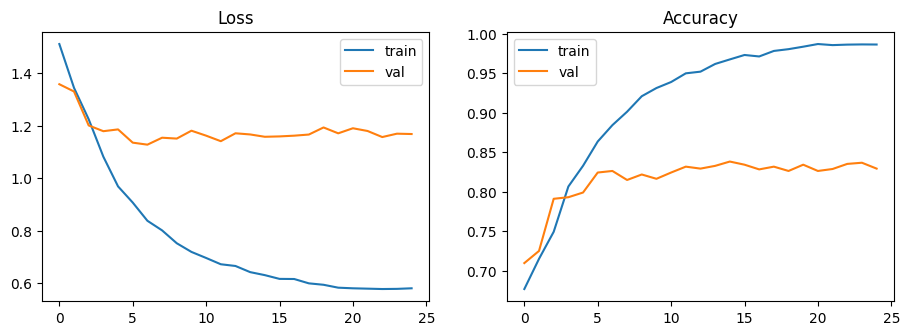

In [ ]:
EPOCHS, FREEZE_EPOCHS = 25, 2
criterion = nn.CrossEntropyLoss(weight=cw, label_smoothing=0.05)
head_params = [p for n, p in model.named_parameters() if not n.startswith("backbone")]
opt = torch.optim.AdamW([{"params": model.backbone.parameters(), "lr": 1e-4},
                         {"params": head_params, "lr": 1e-3}], weight_decay=1e-4)
sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=EPOCHS)
scaler = torch.amp.GradScaler(enabled=device.type == "cuda")

def run_epoch(dl, train):
    model.train(train)
    tot_loss = correct = n = 0
    with torch.set_grad_enabled(train):
        for xb, yb in dl:
            xb, yb = xb.to(device, non_blocking=True), yb.to(device, non_blocking=True)
            with torch.autocast(device_type=device.type, enabled=device.type == "cuda"):
                out = model(xb); loss = criterion(out, yb)
            if train:
                opt.zero_grad(set_to_none=True)
                scaler.scale(loss).backward(); scaler.step(opt); scaler.update()
            tot_loss += loss.item() * len(yb); correct += (out.argmax(1) == yb).sum().item(); n += len(yb)
    return tot_loss / n, correct / n

history = {"tr_loss": [], "va_loss": [], "tr_acc": [], "va_acc": []}
best_acc = 0
for ep in range(EPOCHS):
    for p in model.backbone.parameters(): p.requires_grad = ep >= FREEZE_EPOCHS
    t0 = time.time()
    trl, tra = run_epoch(train_dl, True)
    val, vaa = run_epoch(val_dl, False)
    sched.step()
    for k, v in zip(history, [trl, val, tra, vaa]): history[k].append(v)
    if vaa > best_acc:
        best_acc = vaa; torch.save(model.state_dict(), "best_model.pth")
    print(f"Epoch {ep+1:02d}/{EPOCHS} | train loss {trl:.3f} acc {tra:.3f} | val loss {val:.3f} acc {vaa:.3f} | {time.time()-t0:.0f}s")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].plot(history["tr_loss"], label="train"); ax[0].plot(history["va_loss"], label="val"); ax[0].set_title("Loss"); ax[0].legend()
ax[1].plot(history["tr_acc"], label="train"); ax[1].plot(history["va_acc"], label="val"); ax[1].set_title("Accuracy"); ax[1].legend()
plt.show()

## 7. Evaluation
Because of class imbalance, look at per-class recall and balanced accuracy, not just overall accuracy.

Overall accuracy (with TTA): 0.8381
              precision    recall  f1-score   support

       akiec      0.560     0.691     0.618        68
         bcc      0.676     0.690     0.683       100
         bkl      0.758     0.566     0.648       205
          df      0.625     0.455     0.526        22
         mel      0.646     0.559     0.599       222
          nv      0.904     0.949     0.926      1363
        vasc      0.778     0.824     0.800        34

    accuracy                          0.838      2014
   macro avg      0.707     0.676     0.686      2014
weighted avg      0.833     0.838     0.833      2014

Balanced accuracy: 0.676


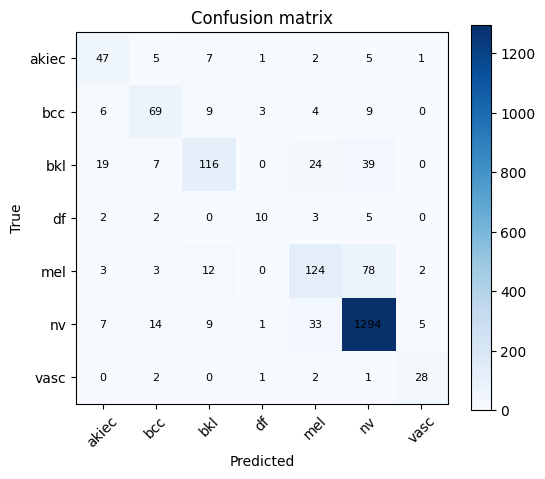

In [ ]:
model.load_state_dict(torch.load("best_model.pth", map_location=device)); model.eval()
y_true, y_pred = [], []
def predict_tta(xb):
    # test-time augmentation: average softmax over original + flips
    views = [xb, xb.flip(3), xb.flip(2), xb.flip(2).flip(3)]
    return torch.stack([torch.softmax(model(v), 1) for v in views]).mean(0)
with torch.no_grad():
    for xb, yb in val_dl:
        y_pred += predict_tta(xb.to(device)).argmax(1).cpu().tolist(); y_true += yb.tolist()
print("Overall accuracy (with TTA):", round(float(np.mean(np.array(y_true) == np.array(y_pred))), 4))

print(classification_report(y_true, y_pred, target_names=classes, digits=3))
print("Balanced accuracy:", round(balanced_accuracy_score(y_true, y_pred), 3))

cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(6, 5)); plt.imshow(cm, cmap="Blues"); plt.colorbar()
plt.xticks(range(len(classes)), classes, rotation=45); plt.yticks(range(len(classes)), classes)
for i in range(len(classes)):
    for j in range(len(classes)): plt.text(j, i, cm[i, j], ha="center", va="center", fontsize=8)
plt.xlabel("Predicted"); plt.ylabel("True"); plt.title("Confusion matrix"); plt.show()

## 8. Grad-CAM (visual explanation)
Gradients of the predicted class are propagated back through the GAT to the EfficientNet feature map to highlight influential regions.

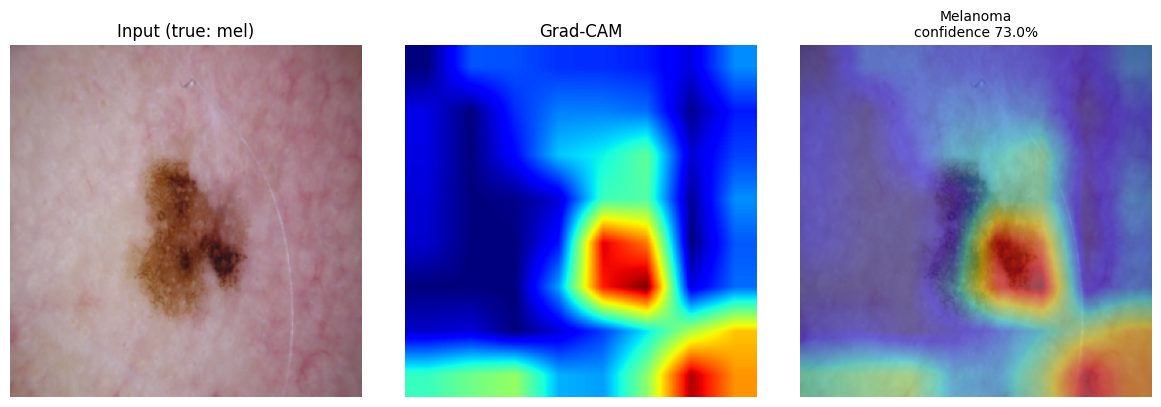

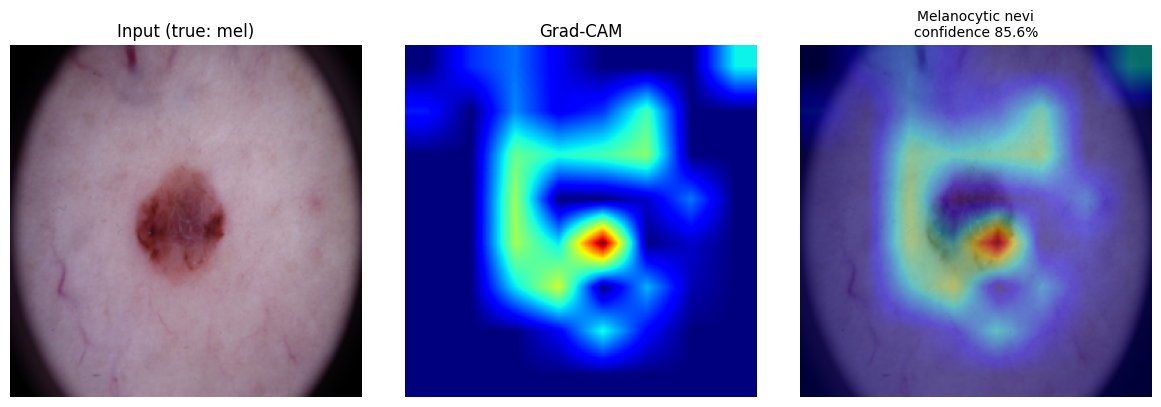

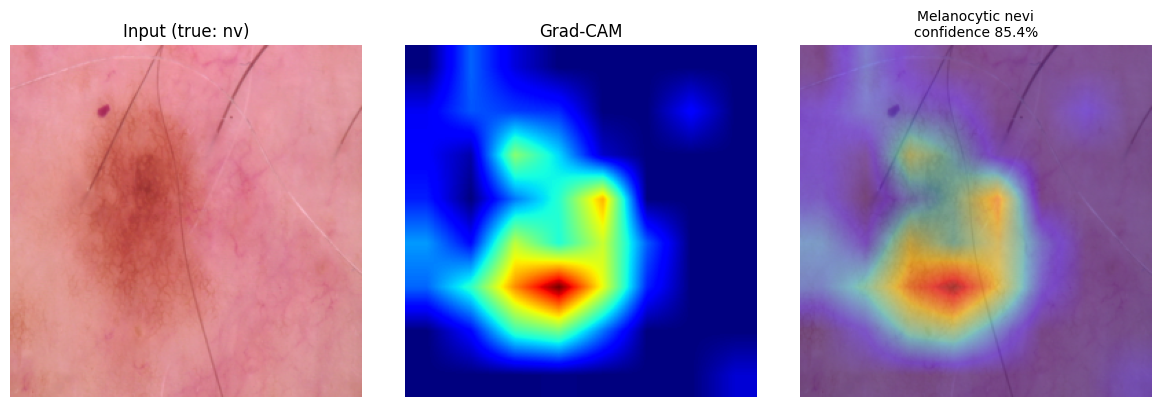

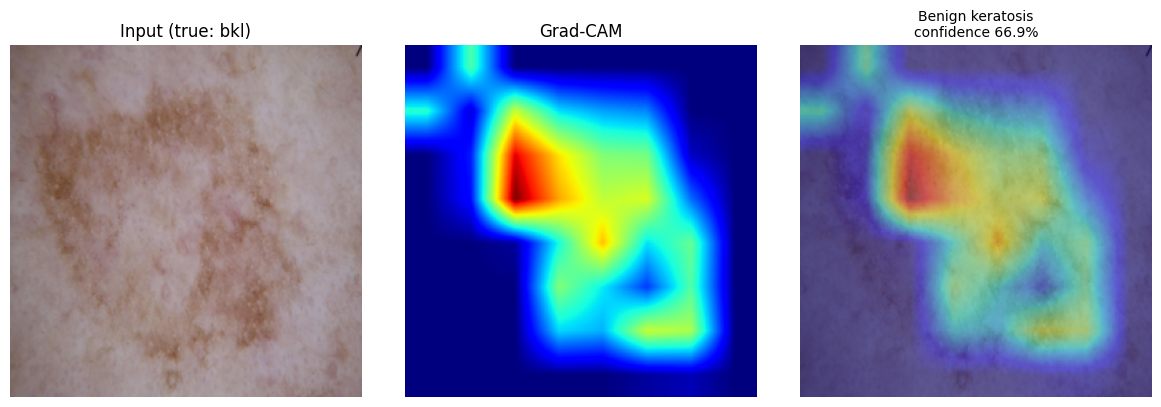

In [ ]:
def grad_cam(img_pil, target=None):
    model.eval()
    x = val_tf(img_pil.convert("RGB")).unsqueeze(0).to(device)
    x.requires_grad_(True)
    logits, fmap = model(x, return_fmap=True)
    probs = torch.softmax(logits, 1)[0]
    c = int(probs.argmax()) if target is None else target
    model.zero_grad(); logits[0, c].backward()
    weights = fmap.grad.mean(dim=(2, 3), keepdim=True)
    cam = F.relu((weights * fmap).sum(1, keepdim=True))
    cam = F.interpolate(cam, size=(IMG, IMG), mode="bilinear", align_corners=False)[0, 0]
    cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)
    return cam.detach().cpu().numpy(), c, probs.detach().cpu().numpy()

def explain(img_pil, true_label=None):
    cam, c, probs = grad_cam(img_pil)
    img = np.array(img_pil.convert("RGB").resize((IMG, IMG))) / 255.0
    heat = plt.cm.jet(cam)[..., :3]
    overlay = 0.55 * img + 0.45 * heat
    fig, ax = plt.subplots(1, 3, figsize=(12, 4))
    ax[0].imshow(img); ax[0].set_title("Input" + (f" (true: {true_label})" if true_label else ""))
    ax[1].imshow(cam, cmap="jet"); ax[1].set_title("Grad-CAM")
    ax[2].imshow(overlay); ax[2].set_title(f"{full_names[classes[c]]}\nconfidence {probs[c]*100:.1f}%", fontsize=10)
    for a in ax: a.axis("off")
    plt.tight_layout(); plt.show()

for _, r in val_df.sample(4, random_state=1).iterrows():
    explain(Image.open(r["path"]), true_label=r["dx"])

## 9a. Quick test with a dataset image (no upload needed)
Run this cell to predict on a random image from the validation set. Run it again for a different image.

True disease: Melanocytic nevi


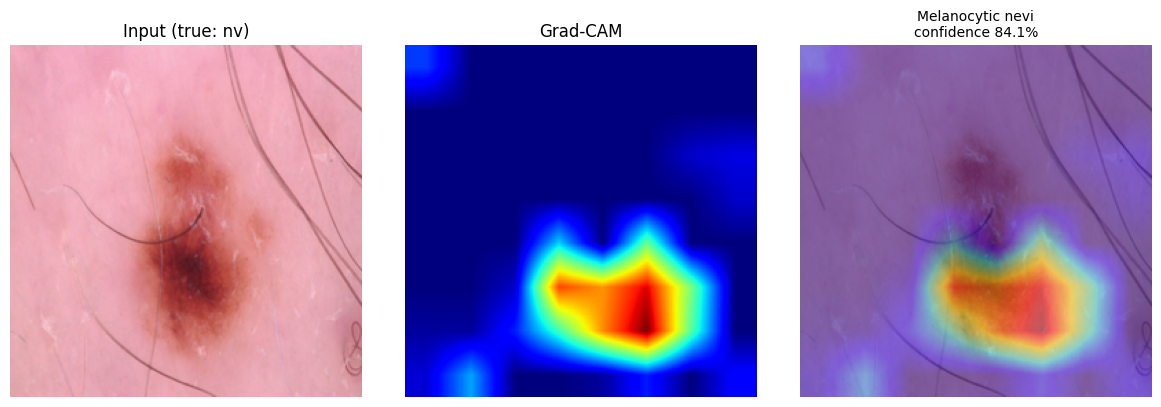

In [ ]:
r = val_df.sample(1).iloc[0]
print("True disease:", full_names[r["dx"]])
explain(Image.open(r["path"]), true_label=r["dx"])

## 9b. Predict on your own image
Upload a skin image to get the predicted class, confidence, and heatmap.

Saving skin image.png to skin image.png


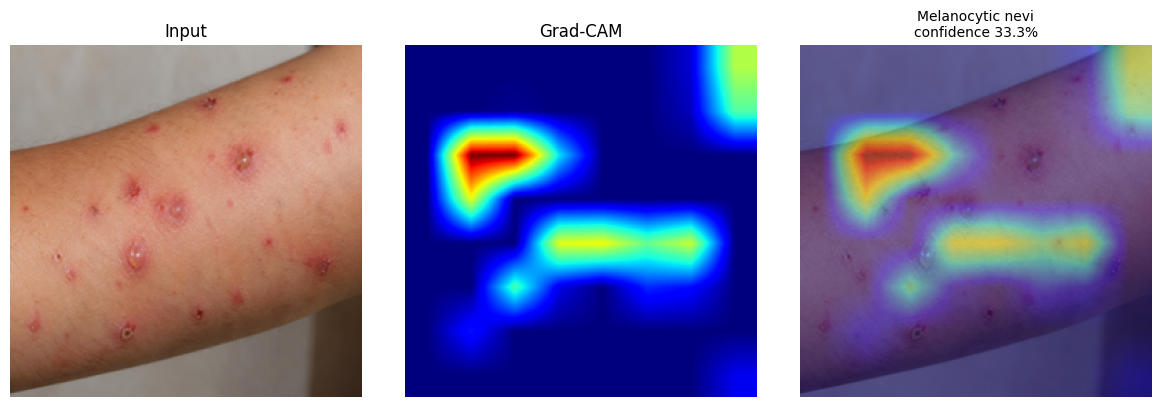

Prediction: Melanocytic nevi (33.3% confidence)

Melanocytic nevi                          33.3%
Vascular lesions                          25.3%
Melanoma                                  23.1%
Basal cell carcinoma                       5.1%
Dermatofibroma                             5.0%
Actinic keratoses / Bowen's disease        4.5%
Benign keratosis                           3.6%


In [ ]:
up = files.upload()
if not up:
    print("No file chosen - click 'Choose files' and select a .jpg/.png image (or use cell 9a instead).")
for fn in up:
    img = Image.open(fn).convert("RGB")
    cam, c, probs = grad_cam(img)
    explain(img)
    print("Prediction:", full_names[classes[c]], f"({probs[c]*100:.1f}% confidence)\n")
    for i in np.argsort(-probs): print(f"{full_names[classes[i]]:40s} {probs[i]*100:5.1f}%")

## Final accuracy summary

In [ ]:
overall = float(np.mean(np.array(y_true) == np.array(y_pred)))
bal = balanced_accuracy_score(y_true, y_pred)
print("=" * 40)
print(f"Validation accuracy (overall): {overall*100:.2f}%")
print(f"Balanced accuracy            : {bal*100:.2f}%")
print(f"Best epoch val accuracy      : {best_acc*100:.2f}%")
print("=" * 40)

Validation accuracy (overall): 83.81%
Balanced accuracy            : 67.61%
Best epoch val accuracy      : 83.81%


## 10. Save the model
Copy the weights to Google Drive so you don't lose them when the Colab session ends.

In [ ]:
try:
    drive.mount("/content/drive")
    shutil.copy("best_model.pth", "/content/drive/MyDrive/skin_effgat_best.pth")
    print("Saved to Google Drive: MyDrive/skin_effgat_best.pth")
except Exception as e:
    print("Google Drive step failed (", e, ") - downloading the model to your computer instead.")
    files.download("best_model.pth")

Google Drive step failed ( Error: credential propagation was unsuccessful ) - downloading the model to your computer instead.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>